In [83]:
from google.colab import files

uploaded = files.upload()


import pandas as pd
import numpy as np
import sqlite3
df = pd.read_csv('WA_Fn-UseC_-Telco-Customer-Churn.csv')
display(df.head())

Saving WA_Fn-UseC_-Telco-Customer-Churn.csv to WA_Fn-UseC_-Telco-Customer-Churn (1).csv


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [84]:
df.shape

(7043, 21)

In [85]:
df.columns

Index(['customerID', 'gender', 'SeniorCitizen', 'Partner', 'Dependents',
       'tenure', 'PhoneService', 'MultipleLines', 'InternetService',
       'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport',
       'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling',
       'PaymentMethod', 'MonthlyCharges', 'TotalCharges', 'Churn'],
      dtype='object')

In [86]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   object 
 1   gender            7043 non-null   object 
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   object 
 4   Dependents        7043 non-null   object 
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   object 
 7   MultipleLines     7043 non-null   object 
 8   InternetService   7043 non-null   object 
 9   OnlineSecurity    7043 non-null   object 
 10  OnlineBackup      7043 non-null   object 
 11  DeviceProtection  7043 non-null   object 
 12  TechSupport       7043 non-null   object 
 13  StreamingTV       7043 non-null   object 
 14  StreamingMovies   7043 non-null   object 
 15  Contract          7043 non-null   object 
 16  PaperlessBilling  7043 non-null   object 


In [87]:


df.isnull().sum()

,0
customerID,0
gender,0
SeniorCitizen,0
Partner,0
Dependents,0
tenure,0
PhoneService,0
MultipleLines,0
InternetService,0
OnlineSecurity,0


In [88]:
df.duplicated().sum()

np.int64(0)

In [89]:
df["TotalCharges"].head(20)

,TotalCharges
0,29.85
1,1889.5
2,108.15
3,1840.75
4,151.65
5,820.5
6,1949.4
7,301.9
8,3046.05
9,3487.95


In [90]:
df["TotalCharges"].str.strip()

,TotalCharges
0,29.85
1,1889.5
2,108.15
3,1840.75
4,151.65
...,...
7038,1990.5
7039,7362.9
7040,346.45
7041,306.6


In [91]:
(df["TotalCharges"].str.strip() == "").sum()

np.int64(11)

In [92]:
df[df["TotalCharges"].str.strip() == ""]

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
488,4472-LVYGI,Female,0,Yes,Yes,0,No,No phone service,DSL,Yes,...,Yes,Yes,Yes,No,Two year,Yes,Bank transfer (automatic),52.55,,No
753,3115-CZMZD,Male,0,No,Yes,0,Yes,No,No,No internet service,...,No internet service,No internet service,No internet service,No internet service,Two year,No,Mailed check,20.25,,No
936,5709-LVOEQ,Female,0,Yes,Yes,0,Yes,No,DSL,Yes,...,Yes,No,Yes,Yes,Two year,No,Mailed check,80.85,,No
1082,4367-NUYAO,Male,0,Yes,Yes,0,Yes,Yes,No,No internet service,...,No internet service,No internet service,No internet service,No internet service,Two year,No,Mailed check,25.75,,No
1340,1371-DWPAZ,Female,0,Yes,Yes,0,No,No phone service,DSL,Yes,...,Yes,Yes,Yes,No,Two year,No,Credit card (automatic),56.05,,No
3331,7644-OMVMY,Male,0,Yes,Yes,0,Yes,No,No,No internet service,...,No internet service,No internet service,No internet service,No internet service,Two year,No,Mailed check,19.85,,No
3826,3213-VVOLG,Male,0,Yes,Yes,0,Yes,Yes,No,No internet service,...,No internet service,No internet service,No internet service,No internet service,Two year,No,Mailed check,25.35,,No
4380,2520-SGTTA,Female,0,Yes,Yes,0,Yes,No,No,No internet service,...,No internet service,No internet service,No internet service,No internet service,Two year,No,Mailed check,20.00,,No
5218,2923-ARZLG,Male,0,Yes,Yes,0,Yes,No,No,No internet service,...,No internet service,No internet service,No internet service,No internet service,One year,Yes,Mailed check,19.70,,No
6670,4075-WKNIU,Female,0,Yes,Yes,0,Yes,Yes,DSL,No,...,Yes,Yes,Yes,No,Two year,No,Mailed check,73.35,,No


In [93]:
df["TotalCharges"] = pd.to_numeric(
    df["TotalCharges"], errors="coerce"
)

In [94]:
df.isnull().sum()

,0
customerID,0
gender,0
SeniorCitizen,0
Partner,0
Dependents,0
tenure,0
PhoneService,0
MultipleLines,0
InternetService,0
OnlineSecurity,0


In [95]:
df["TotalCharges"].dtype

dtype('float64')

In [96]:
df["TotalCharges"].fillna(0)

,TotalCharges
0,29.85
1,1889.50
2,108.15
3,1840.75
4,151.65
...,...
7038,1990.50
7039,7362.90
7040,346.45
7041,306.60


In [97]:
df["TotalCharges"].dtype

dtype('float64')

In [98]:
df["TotalCharges"] = df["TotalCharges"].fillna(0)

In [99]:
df.isnull().sum()

,0
customerID,0
gender,0
SeniorCitizen,0
Partner,0
Dependents,0
tenure,0
PhoneService,0
MultipleLines,0
InternetService,0
OnlineSecurity,0


In [100]:
df["Contract"].unique()

array(['Month-to-month', 'One year', 'Two year'], dtype=object)

In [101]:
categorical_cols = df.select_dtypes(include=["object"]).columns

for col in categorical_cols:
    print("Column:", col)
    print("Unique values:", df[col].unique())
    print("---------------------------")

Column: customerID
Unique values: ['7590-VHVEG' '5575-GNVDE' '3668-QPYBK' ... '4801-JZAZL' '8361-LTMKD'
 '3186-AJIEK']
---------------------------
Column: gender
Unique values: ['Female' 'Male']
---------------------------
Column: Partner
Unique values: ['Yes' 'No']
---------------------------
Column: Dependents
Unique values: ['No' 'Yes']
---------------------------
Column: PhoneService
Unique values: ['No' 'Yes']
---------------------------
Column: MultipleLines
Unique values: ['No phone service' 'No' 'Yes']
---------------------------
Column: InternetService
Unique values: ['DSL' 'Fiber optic' 'No']
---------------------------
Column: OnlineSecurity
Unique values: ['No' 'Yes' 'No internet service']
---------------------------
Column: OnlineBackup
Unique values: ['Yes' 'No' 'No internet service']
---------------------------
Column: DeviceProtection
Unique values: ['No' 'Yes' 'No internet service']
---------------------------
Column: TechSupport
Unique values: ['No' 'Yes' 'No internet

In [102]:
df["customerID"].nunique()

7043

In [103]:
df.describe()

,SeniorCitizen,tenure,MonthlyCharges,TotalCharges
count,7043.000000,7043.000000,7043.000000,7043.000000
mean,0.162147,32.371149,64.761692,2279.734304
std,0.368612,24.559481,30.090047,2266.794470
min,0.000000,0.000000,18.250000,0.000000
25%,0.000000,9.000000,35.500000,398.550000
50%,0.000000,29.000000,70.350000,1394.550000
75%,0.000000,55.000000,89.850000,3786.600000
max,1.000000,72.000000,118.750000,8684.800000


In [104]:
df[(df["PhoneService"] == "No") & (df["MultipleLines"] == "Yes")]

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn


In [105]:
df[(df["InternetService"] == "No") & (df["OnlineSecurity"] == "Yes")]

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn


In [106]:
df[(df["InternetService"] == "No") & (df["OnlineSecurity"] != "No internet service")]

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn


In [107]:
internet_cols = [
    "OnlineBackup",
    "DeviceProtection",
    "TechSupport",
    "StreamingTV",
    "StreamingMovies"
]

for col in internet_cols:
    inconsistent = df[
        (df["InternetService"] == "No") &
        (df[col] != "No internet service")
    ]

    print(col, len(inconsistent))

OnlineBackup 0
DeviceProtection 0
TechSupport 0
StreamingTV 0
StreamingMovies 0


In [108]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   object 
 1   gender            7043 non-null   object 
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   object 
 4   Dependents        7043 non-null   object 
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   object 
 7   MultipleLines     7043 non-null   object 
 8   InternetService   7043 non-null   object 
 9   OnlineSecurity    7043 non-null   object 
 10  OnlineBackup      7043 non-null   object 
 11  DeviceProtection  7043 non-null   object 
 12  TechSupport       7043 non-null   object 
 13  StreamingTV       7043 non-null   object 
 14  StreamingMovies   7043 non-null   object 
 15  Contract          7043 non-null   object 
 16  PaperlessBilling  7043 non-null   object 


In [109]:
import sqlite3

conn = sqlite3.connect("customer_churn.db")

df.to_sql("customers", conn, if_exists="replace", index=False)


7043

In [110]:
pd.read_sql_query("SELECT * FROM customers LIMIT 5", conn)

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.50,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [111]:
pd.read_sql_query("""
SELECT Churn, COUNT(customerID) AS CustomerCount
FROM customers
GROUP BY Churn;
""", conn)

,Churn,CustomerCount
0,No,5174
1,Yes,1869


In [112]:
pd.read_sql_query("SELECT 1869 * 100.0 / 7043 AS ChurnRate;",conn)

,ChurnRate
0,26.536987


In [113]:
pd.read_sql_query("""
SELECT
    COUNT(*) * 100.0 /
    (SELECT COUNT(*) FROM customers) AS ChurnRate
FROM customers
WHERE Churn = 'Yes';
""", conn)

,ChurnRate
0,26.536987


In [114]:
pd.read_sql_query("""
SELECT Contract, COUNT(*) AS ChurnedCustomers
FROM customers
WHERE Churn = 'Yes'
GROUP BY Contract;
""", conn)

,Contract,ChurnedCustomers
0,Month-to-month,1655
1,One year,166
2,Two year,48


In [115]:
pd.read_sql_query("""
SELECT Contract, COUNT(customerid) as totalcustomers
FROM customers
GROUP BY Contract;
""", conn)

,Contract,totalcustomers
0,Month-to-month,3875
1,One year,1473
2,Two year,1695


In [116]:
pd.read_sql_query(""" SELECT
    Contract,
    COUNT(*) AS TotalCustomers,
    SUM(
        CASE
            WHEN Churn = 'Yes' THEN 1
            ELSE 0
        END
    ) AS ChurnedCustomers
FROM customers
GROUP BY Contract;""",conn)

,Contract,TotalCustomers,ChurnedCustomers
0,Month-to-month,3875,1655
1,One year,1473,166
2,Two year,1695,48


In [117]:



pd.read_sql_query("""
SELECT
    Contract,
    COUNT(*) AS TotalCustomers,

    SUM(
        CASE
            WHEN Churn = 'Yes' THEN 1
            ELSE 0
        END
    ) AS ChurnedCustomers,

    ROUND(
        SUM(
            CASE
                WHEN Churn = 'Yes' THEN 1
                ELSE 0
            END
        ) * 100.0 / COUNT(*),
        2
    ) AS ChurnRate

FROM customers
GROUP BY Contract;
""", conn)

,Contract,TotalCustomers,ChurnedCustomers,ChurnRate
0,Month-to-month,3875,1655,42.71
1,One year,1473,166,11.27
2,Two year,1695,48,2.83


In [118]:
pd.read_sql_query("""
SELECT
    Contract, sum(monthlycharges) as totalmonthlycharges
FROM customers
GROUP BY Contract;

""", conn)

,Contract,totalmonthlycharges
0,Month-to-month,257294.15
1,One year,95816.60
2,Two year,103005.85


In [119]:
pd.read_sql_query("""
SELECT
    Contract, sum(monthlycharges) as activemonthlycharges
FROM customers
where Churn = 'No'
GROUP BY Contract;

""", conn)

,Contract,activemonthlycharges
0,Month-to-month,136447.05
1,One year,81698.15
2,Two year,98840.55


In [120]:
pd.read_sql_query("""
SELECT
   PaymentMethod , count(churn) as churnedcustomers
FROM customers
where Churn = 'Yes'
GROUP BY paymentmethod;

""", conn)

,PaymentMethod,churnedcustomers
0,Bank transfer (automatic),258
1,Credit card (automatic),232
2,Electronic check,1071
3,Mailed check,308


In [121]:
pd.read_sql_query("""
SELECT
    PaymentMethod,
    COUNT(customerID) AS TotalCustomers,

    SUM(
        CASE
            WHEN Churn = 'Yes' THEN 1
            ELSE 0
        END
    ) AS ChurnedCustomers,

    ROUND(
        SUM(
            CASE
                WHEN Churn = 'Yes' THEN 1
                ELSE 0
            END
        ) * 100.0 / COUNT(*),
        2
    ) AS ChurnRate

FROM customers
GROUP BY PaymentMethod;
""", conn)

,PaymentMethod,TotalCustomers,ChurnedCustomers,ChurnRate
0,Bank transfer (automatic),1544,258,16.71
1,Credit card (automatic),1522,232,15.24
2,Electronic check,2365,1071,45.29
3,Mailed check,1612,308,19.11


In [122]:
pd.read_sql_query("""
SELECT
    Contract,
    PaymentMethod,
    COUNT(customerID) AS TotalCustomers
FROM customers
GROUP BY Contract, PaymentMethod;
""", conn)

,Contract,PaymentMethod,TotalCustomers
0,Month-to-month,Bank transfer (automatic),589
1,Month-to-month,Credit card (automatic),543
2,Month-to-month,Electronic check,1850
3,Month-to-month,Mailed check,893
4,One year,Bank transfer (automatic),391
5,One year,Credit card (automatic),398
6,One year,Electronic check,347
7,One year,Mailed check,337
8,Two year,Bank transfer (automatic),564
9,Two year,Credit card (automatic),581


In [123]:
pd.read_sql_query("""
SELECT
    Contract,
    PaymentMethod,
    COUNT(customerID) AS TotalCustomers,
    SUM(
        CASE
            WHEN Churn = 'Yes' THEN 1
            ELSE 0
        END
    ) AS ChurnedCustomers
FROM customers
GROUP BY Contract, PaymentMethod;
""", conn)

,Contract,PaymentMethod,TotalCustomers,ChurnedCustomers
0,Month-to-month,Bank transfer (automatic),589,201
1,Month-to-month,Credit card (automatic),543,178
2,Month-to-month,Electronic check,1850,994
3,Month-to-month,Mailed check,893,282
4,One year,Bank transfer (automatic),391,38
5,One year,Credit card (automatic),398,41
6,One year,Electronic check,347,64
7,One year,Mailed check,337,23
8,Two year,Bank transfer (automatic),564,19
9,Two year,Credit card (automatic),581,13


In [124]:
pd.read_sql_query("""
SELECT
    Contract,
    PaymentMethod,
    COUNT(*) AS TotalCustomers,

    SUM(
        CASE
            WHEN Churn = 'Yes' THEN 1
            ELSE 0
        END
    ) AS ChurnedCustomers,

    ROUND(
        SUM(
            CASE
                WHEN Churn = 'Yes' THEN 1
                ELSE 0
            END
        ) * 100.0 / COUNT(*),
        2
    ) AS ChurnRate

FROM customers
GROUP BY Contract, PaymentMethod
ORDER BY Contract, ChurnRate DESC;
""", conn)

,Contract,PaymentMethod,TotalCustomers,ChurnedCustomers,ChurnRate
0,Month-to-month,Electronic check,1850,994,53.73
1,Month-to-month,Bank transfer (automatic),589,201,34.13
2,Month-to-month,Credit card (automatic),543,178,32.78
3,Month-to-month,Mailed check,893,282,31.58
4,One year,Electronic check,347,64,18.44
5,One year,Credit card (automatic),398,41,10.30
6,One year,Bank transfer (automatic),391,38,9.72
7,One year,Mailed check,337,23,6.82
8,Two year,Electronic check,168,13,7.74
9,Two year,Bank transfer (automatic),564,19,3.37


In [125]:
pd.read_sql_query("""
SELECT
    PaymentMethod,
    ROUND(AVG(tenure), 2) AS AverageTenure
FROM customers
GROUP BY PaymentMethod;
""", conn)

,PaymentMethod,AverageTenure
0,Bank transfer (automatic),43.66
1,Credit card (automatic),43.27
2,Electronic check,25.17
3,Mailed check,21.83


In [126]:
pd.read_sql_query("""
SELECT
    Churn,
    ROUND(AVG(tenure), 2) AS AverageTenure
FROM customers
WHERE Contract = 'Month-to-month'
GROUP BY Churn;
""", conn)

,Churn,AverageTenure
0,No,21.03
1,Yes,14.02


In [127]:
pd.read_sql_query("""
SELECT
    CASE
        WHEN tenure <= 12 THEN '0-12 months'
        WHEN tenure <= 24 THEN '13-24 months'
        WHEN tenure <= 48 THEN '25-48 months'
        ELSE '49-72 months'
    END AS TenureGroup,

    COUNT(*) AS TotalCustomers

FROM customers
GROUP BY TenureGroup
ORDER BY MIN(tenure);
""", conn)

,TenureGroup,TotalCustomers
0,0-12 months,2186
1,13-24 months,1024
2,25-48 months,1594
3,49-72 months,2239


In [128]:
pd.read_sql_query("""
SELECT
    CASE
        WHEN tenure <= 12 THEN '0-12 months'
        WHEN tenure <= 24 THEN '13-24 months'
        WHEN tenure <= 48 THEN '25-48 months'
        ELSE '49-72 months'
    END AS TenureGroup,

    COUNT(*) AS TotalCustomers,

    SUM(
        CASE
            WHEN Churn = 'Yes' THEN 1
            ELSE 0
        END
    ) AS ChurnedCustomers,

    ROUND(
        SUM(
            CASE
                WHEN Churn = 'Yes' THEN 1
                ELSE 0
            END
        ) * 100.0 / COUNT(*),
        2
    ) AS ChurnRate

FROM customers
GROUP BY TenureGroup
ORDER BY MIN(tenure);
""", conn)

,TenureGroup,TotalCustomers,ChurnedCustomers,ChurnRate
0,0-12 months,2186,1037,47.44
1,13-24 months,1024,294,28.71
2,25-48 months,1594,325,20.39
3,49-72 months,2239,213,9.51


In [129]:
pd.read_sql_query("""
SELECT
    Churn,
    ROUND(AVG(MonthlyCharges), 2) AS AverageMonthlyCharges
FROM customers
GROUP BY Churn;
""", conn)

,Churn,AverageMonthlyCharges
0,No,61.27
1,Yes,74.44


In [130]:
pd.read_sql_query("""
SELECT
contract,
    Churn,
    ROUND(AVG(MonthlyCharges), 2) AS AverageMonthlyCharges
FROM customers
GROUP BY contract , churn;
""", conn)

,Contract,Churn,AverageMonthlyCharges
0,Month-to-month,No,61.46
1,Month-to-month,Yes,73.02
2,One year,No,62.51
3,One year,Yes,85.05
4,Two year,No,60.01
5,Two year,Yes,86.78


In [131]:
pd.read_sql_query("""
SELECT
internetservice,
    ROUND(AVG(MonthlyCharges), 2) AS AverageMonthlyCharges
FROM customers
GROUP BY internetservice
""", conn)

,InternetService,AverageMonthlyCharges
0,DSL,58.10
1,Fiber optic,91.50
2,No,21.08


In [132]:
pd.read_sql_query("""
SELECT
   internetservice,

    COUNT(*) AS TotalCustomers,

    SUM(
        CASE
            WHEN Churn = 'Yes' THEN 1
            ELSE 0
        END
    ) AS ChurnedCustomers,

    ROUND(
        SUM(
            CASE
                WHEN Churn = 'Yes' THEN 1
                ELSE 0
            END
        ) * 100.0 / COUNT(*),
        2
    ) AS ChurnRate

FROM customers
GROUP BY internetservice;
""", conn)

,InternetService,TotalCustomers,ChurnedCustomers,ChurnRate
0,DSL,2421,459,18.96
1,Fiber optic,3096,1297,41.89
2,No,1526,113,7.40


In [133]:
pd.read_sql_query("""
SELECT
churn,
internetservice,
    ROUND(AVG(MonthlyCharges), 2) AS AverageMonthlyCharges
FROM customers
GROUP BY internetservice, churn
""", conn)

,Churn,InternetService,AverageMonthlyCharges
0,No,DSL,60.21
1,Yes,DSL,49.08
2,No,Fiber optic,93.93
3,Yes,Fiber optic,88.13
4,No,No,21.14
5,Yes,No,20.37


In [134]:
pd.read_sql_query("""
SELECT
   techsupport,

    COUNT(*) AS TotalCustomers,

    SUM(
        CASE
            WHEN Churn = 'Yes' THEN 1
            ELSE 0
        END
    ) AS ChurnedCustomers,

    ROUND(
        SUM(
            CASE
                WHEN Churn = 'Yes' THEN 1
                ELSE 0
            END
        ) * 100.0 / COUNT(*),
        2
    ) AS ChurnRate

FROM customers
GROUP BY techsupport;
""", conn)

,TechSupport,TotalCustomers,ChurnedCustomers,ChurnRate
0,No,3473,1446,41.64
1,No internet service,1526,113,7.40
2,Yes,2044,310,15.17


In [135]:
pd.read_sql_query("""
SELECT
   techsupport,internetservice,

    COUNT(*) AS TotalCustomers,

    SUM(
        CASE
            WHEN Churn = 'Yes' THEN 1
            ELSE 0
        END
    ) AS ChurnedCustomers,

    ROUND(
        SUM(
            CASE
                WHEN Churn = 'Yes' THEN 1
                ELSE 0
            END
        ) * 100.0 / COUNT(*),
        2
    ) AS ChurnRate

FROM customers
GROUP BY techsupport , internetservice;
""", conn)

,TechSupport,InternetService,TotalCustomers,ChurnedCustomers,ChurnRate
0,No,DSL,1243,345,27.76
1,No,Fiber optic,2230,1101,49.37
2,No internet service,No,1526,113,7.40
3,Yes,DSL,1178,114,9.68
4,Yes,Fiber optic,866,196,22.63


In [136]:
pd.read_sql_query("""
SELECT
   partner,

    COUNT(*) AS TotalCustomers,

    SUM(
        CASE
            WHEN Churn = 'Yes' THEN 1
            ELSE 0
        END
    ) AS ChurnedCustomers,

    ROUND(
        SUM(
            CASE
                WHEN Churn = 'Yes' THEN 1
                ELSE 0
            END
        ) * 100.0 / COUNT(*),
        2
    ) AS ChurnRate

FROM customers
GROUP BY partner;
""", conn)

,Partner,TotalCustomers,ChurnedCustomers,ChurnRate
0,No,3641,1200,32.96
1,Yes,3402,669,19.66


In [137]:
pd.read_sql_query("""
SELECT
   dependents,

    COUNT(*) AS TotalCustomers,

    SUM(
        CASE
            WHEN Churn = 'Yes' THEN 1
            ELSE 0
        END
    ) AS ChurnedCustomers,

    ROUND(
        SUM(
            CASE
                WHEN Churn = 'Yes' THEN 1
                ELSE 0
            END
        ) * 100.0 / COUNT(*),
        2
    ) AS ChurnRate

FROM customers
GROUP BY dependents;
""", conn)

,Dependents,TotalCustomers,ChurnedCustomers,ChurnRate
0,No,4933,1543,31.28
1,Yes,2110,326,15.45


In [138]:
pd.read_sql_query("""
SELECT
   seniorcitizen,

    COUNT(*) AS TotalCustomers,

    SUM(
        CASE
            WHEN Churn = 'Yes' THEN 1
            ELSE 0
        END
    ) AS ChurnedCustomers,

    ROUND(
        SUM(
            CASE
                WHEN Churn = 'Yes' THEN 1
                ELSE 0
            END
        ) * 100.0 / COUNT(*),
        2
    ) AS ChurnRate

FROM customers
GROUP BY seniorcitizen;
""", conn)

,SeniorCitizen,TotalCustomers,ChurnedCustomers,ChurnRate
0,0,5901,1393,23.61
1,1,1142,476,41.68


In [139]:
pd.read_sql_query("""
SELECT
    COUNT(*) AS TotalCustomers,

    SUM(
        CASE
            WHEN Churn = 'Yes' THEN 1
            ELSE 0
        END
    ) AS ChurnedCustomers,

    ROUND(
        SUM(
            CASE
                WHEN Churn = 'Yes' THEN 1
                ELSE 0
            END
        ) * 100.0 / COUNT(*),
        2
    ) AS ChurnRate

FROM customers
WHERE Contract = 'Month-to-month'
  AND InternetService = 'Fiber optic'
  AND TechSupport = 'No';
""", conn)

,TotalCustomers,ChurnedCustomers,ChurnRate
0,1796,1033,57.52


In [140]:
print(df["TotalCharges"].dtype)

float64


In [141]:
print(df["TotalCharges"].isnull().sum())

0


In [142]:
print(df.loc[df["tenure"] == 0, ["tenure", "TotalCharges"]])

      tenure  TotalCharges
488        0           0.0
753        0           0.0
936        0           0.0
1082       0           0.0
1340       0           0.0
3331       0           0.0
3826       0           0.0
4380       0           0.0
5218       0           0.0
6670       0           0.0
6754       0           0.0


In [143]:
import matplotlib.pyplot as plt
import seaborn as sns

In [144]:
contract_churn = (
    df.groupby("Contract")["Churn"]
      .apply(lambda x: (x == "Yes").mean() * 100)
      .reset_index(name="ChurnRate")
)

print(contract_churn)

         Contract  ChurnRate
0  Month-to-month  42.709677
1        One year  11.269518
2        Two year   2.831858


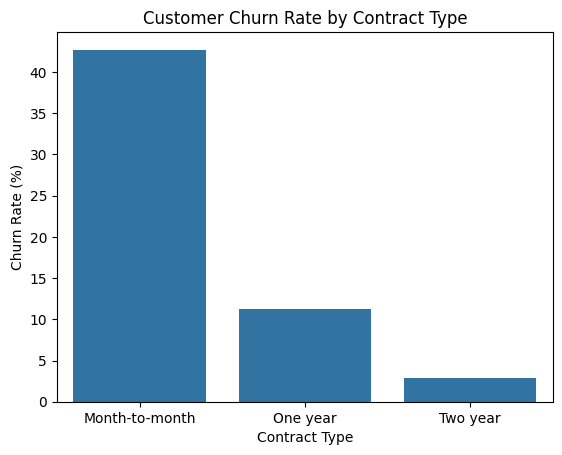

In [145]:
sns.barplot(
    data=contract_churn,
    x="Contract",
    y="ChurnRate",
    order=["Month-to-month", "One year", "Two year"]
)

plt.title("Customer Churn Rate by Contract Type")
plt.xlabel("Contract Type")
plt.ylabel("Churn Rate (%)")
plt.show()

In [146]:
payment_churn =(
    df.groupby("PaymentMethod")["Churn"]
    .apply(lambda x: (x == "Yes").mean()*100)
    .reset_index(name="ChurnRate")
)

print(payment_churn)


               PaymentMethod  ChurnRate
0  Bank transfer (automatic)  16.709845
1    Credit card (automatic)  15.243101
2           Electronic check  45.285412
3               Mailed check  19.106700


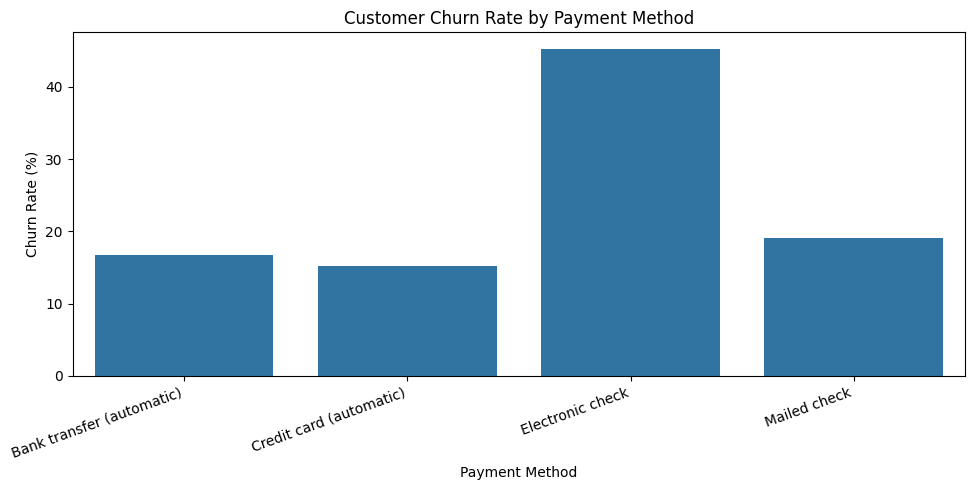

In [147]:
plt.figure(figsize=(10,5))

sns.barplot(data=payment_churn, x = "PaymentMethod", y = "ChurnRate")
plt.title("Customer Churn Rate by Payment Method")
plt.xlabel("Payment Method")
plt.ylabel("Churn Rate (%)")
plt.xticks(rotation=20, ha="right")
plt.tight_layout()
plt.show()

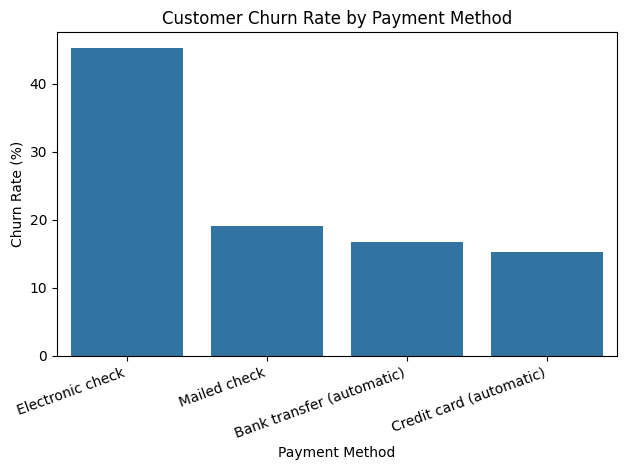

In [148]:
payment_churn = payment_churn.sort_values(
    by="ChurnRate",
    ascending=False
)

sns.barplot(
    data=payment_churn,
    x="PaymentMethod",
    y="ChurnRate",
    order=payment_churn["PaymentMethod"]
)

plt.title("Customer Churn Rate by Payment Method")
plt.xlabel("Payment Method")
plt.ylabel("Churn Rate (%)")
plt.xticks(rotation=20, ha="right")
plt.tight_layout()
plt.show()

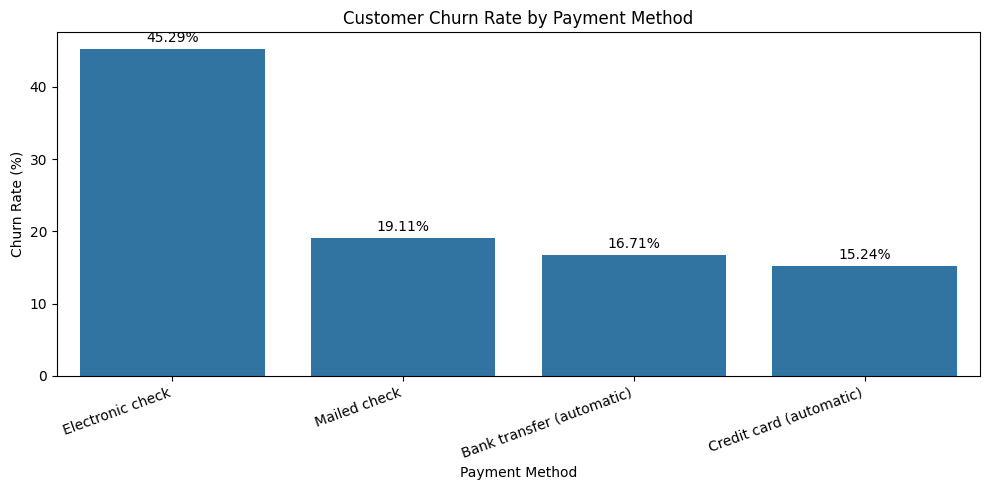

In [149]:
plt.figure(figsize=(10, 5))

ax = sns.barplot(
    data=payment_churn,
    x="PaymentMethod",
    y="ChurnRate"
)

for bar in ax.containers:
    ax.bar_label(bar, fmt="%.2f%%", padding=3)

plt.title("Customer Churn Rate by Payment Method")
plt.xlabel("Payment Method")
plt.ylabel("Churn Rate (%)")
plt.xticks(rotation=20, ha="right")
plt.tight_layout()
plt.show()

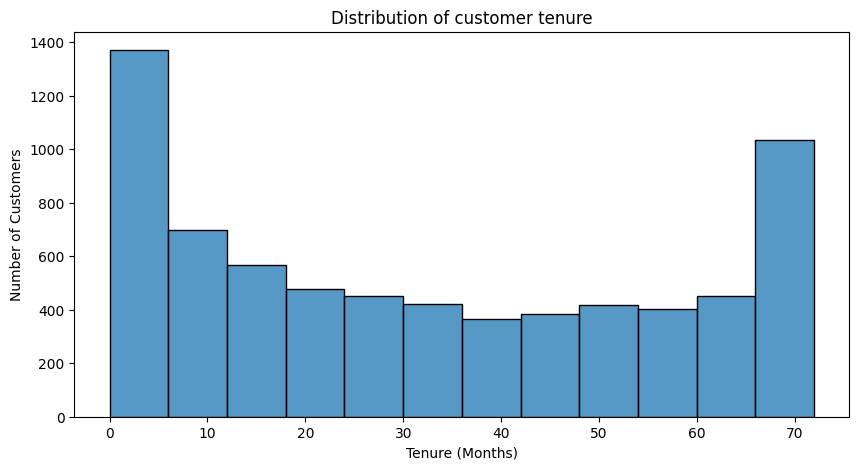

In [150]:
plt.figure(figsize=(10,5))

sns.histplot(data = df, x = "tenure",bins = 12)
plt.title("Distribution of customer tenure")
plt.xlabel("Tenure (Months)")
plt.ylabel("Number of Customers")
plt.show()

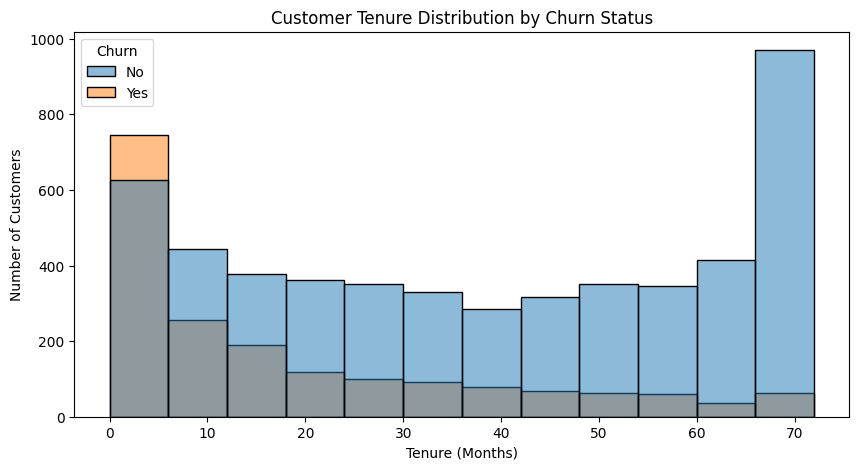

In [151]:
plt.figure(figsize=(10, 5))

sns.histplot(
    data=df,
    x="tenure",
    hue="Churn",
    bins=12,
    multiple="layer",
    alpha=0.5
)

plt.title("Customer Tenure Distribution by Churn Status")
plt.xlabel("Tenure (Months)")
plt.ylabel("Number of Customers")
plt.show()

In [152]:
import numpy as np
import pandas as pd

tenure_bins = np.arange(0, 79, 6)

df["TenureGroup6M"] = pd.cut(
    df["tenure"],
    bins=tenure_bins,
    include_lowest=True
)

tenure_churn = (
    df.groupby("TenureGroup6M", observed=True)["Churn"]
      .apply(lambda x: (x == "Yes").mean() * 100)
      .reset_index(name="ChurnRate")
)

print(tenure_churn)

    TenureGroup6M  ChurnRate
0   (-0.001, 6.0]  52.937205
1     (6.0, 12.0]  35.886525
2    (12.0, 18.0]  32.299270
3    (18.0, 24.0]  24.579832
4    (24.0, 30.0]  21.809745
5    (30.0, 36.0]  21.446384
6    (36.0, 42.0]  21.899736
7    (42.0, 48.0]  16.187990
8    (48.0, 54.0]  16.190476
9    (54.0, 60.0]  12.621359
10   (60.0, 66.0]   9.287257
11   (66.0, 72.0]   5.296610


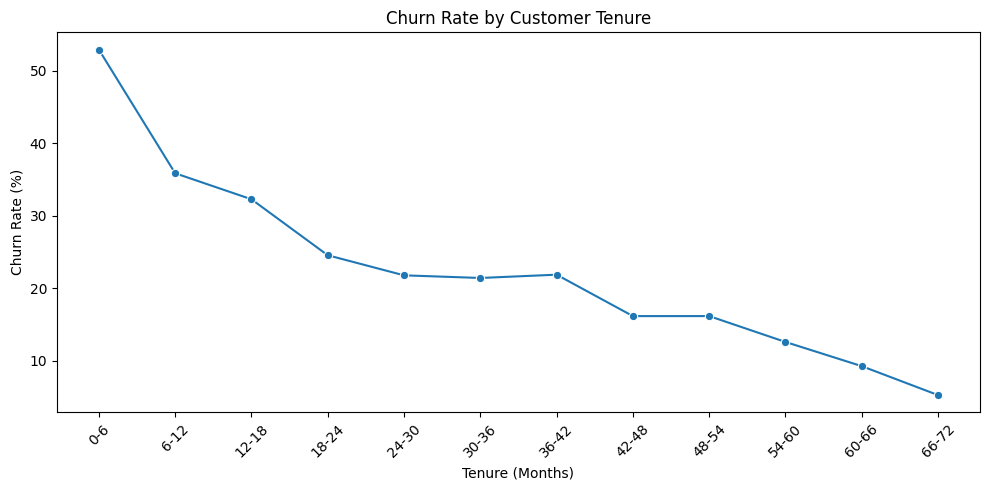

In [153]:
plt.figure(figsize=(10, 5))

sns.lineplot(
    data=tenure_churn,
    x=range(len(tenure_churn)),
    y="ChurnRate",
    marker="o"
)

plt.xticks(
    ticks=range(len(tenure_churn)),
    labels=[f"{i*6}-{(i+1)*6}" for i in range(len(tenure_churn))],
    rotation=45
)

plt.title("Churn Rate by Customer Tenure")
plt.xlabel("Tenure (Months)")
plt.ylabel("Churn Rate (%)")
plt.tight_layout()
plt.show()

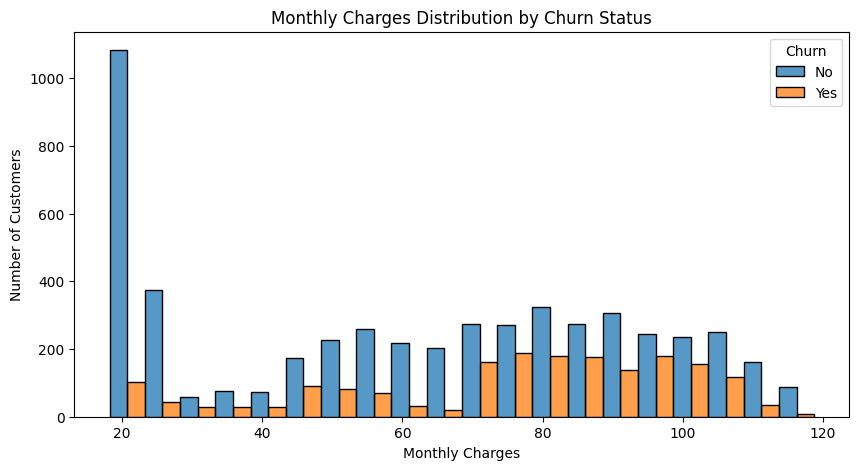

In [154]:
plt.figure(figsize=(10, 5))

sns.histplot(
    data=df,
    x="MonthlyCharges",
    hue="Churn",
    bins=20,
    multiple="dodge"
)

plt.title("Monthly Charges Distribution by Churn Status")
plt.xlabel("Monthly Charges")
plt.ylabel("Number of Customers")
plt.show()

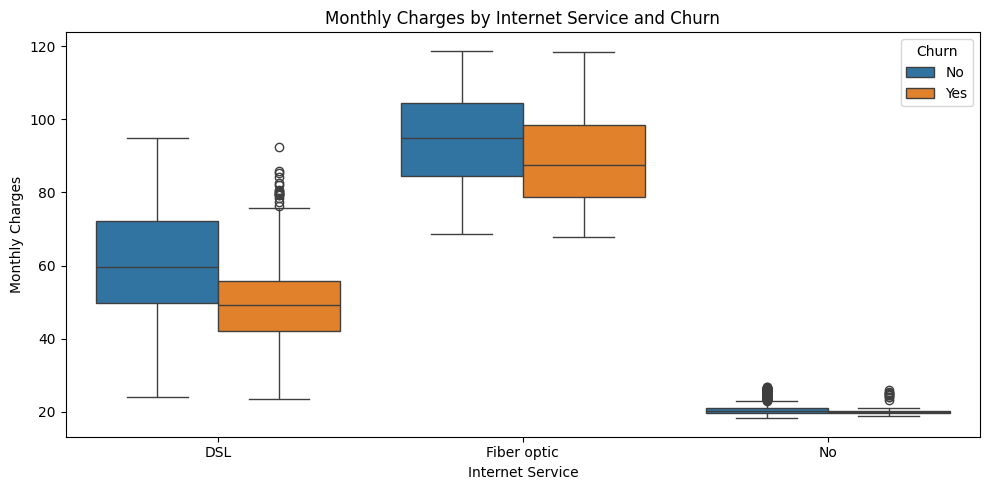

In [155]:
plt.figure(figsize=(10, 5))

sns.boxplot(
    data=df,
    x="InternetService",
    y="MonthlyCharges",
    hue="Churn"
)

plt.title("Monthly Charges by Internet Service and Churn")
plt.xlabel("Internet Service")
plt.ylabel("Monthly Charges")
plt.tight_layout()
plt.show()

In [156]:
import pandas as pd

contract_table = pd.crosstab(
    df["Contract"],
    df["Churn"]
)

print(contract_table)

Churn             No   Yes
Contract                  
Month-to-month  2220  1655
One year        1307   166
Two year        1647    48


In [157]:
from scipy.stats import chi2_contingency

chi2, p_value, dof, expected = chi2_contingency(contract_table)

print("Chi-square statistic:", chi2)
print("P-value:", p_value)
print("Degrees of freedom:", dof)

Chi-square statistic: 1184.5965720837926
P-value: 5.863038300673391e-258
Degrees of freedom: 2


In [158]:
expected_table = pd.DataFrame(
    expected,
    index=contract_table.index,
    columns=contract_table.columns
)

print(expected_table.round(2))

Churn                No      Yes
Contract                        
Month-to-month  2846.69  1028.31
One year        1082.11   390.89
Two year        1245.20   449.80


In [159]:
import numpy as np

n = contract_table.to_numpy().sum()

r, c = contract_table.shape

cramers_v = np.sqrt(
    chi2 / (n * min(r - 1, c - 1))
)

print("Cramér's V:", round(cramers_v, 4))

Cramér's V: 0.4101


In [160]:
from scipy.stats import chi2_contingency
import numpy as np

payment_table = pd.crosstab(
    df["PaymentMethod"],
    df["Churn"]
)

payment_chi2, payment_p, payment_dof, payment_expected = chi2_contingency(
    payment_table
)

payment_n = payment_table.to_numpy().sum()
r, c = payment_table.shape

payment_v = np.sqrt(
    payment_chi2 / (payment_n * min(r - 1, c - 1))
)

print("Chi-square:", payment_chi2)
print("P-value:", payment_p)
print("Degrees of freedom:", payment_dof)
print("Cramér's V:", round(payment_v, 4))

Chi-square: 648.1423274814
P-value: 3.6823546520097993e-140
Degrees of freedom: 3
Cramér's V: 0.3034


In [161]:
internet_table = pd.crosstab(
    df["InternetService"],
    df["Churn"]
)

internet_chi2, internet_p, internet_dof, internet_expected = chi2_contingency(
    internet_table
)

n = internet_table.to_numpy().sum()
r, c = internet_table.shape

internet_v = np.sqrt(
    internet_chi2 / (n * min(r - 1, c - 1))
)

print("Chi-square:", internet_chi2)
print("P-value:", internet_p)
print("Degrees of freedom:", internet_dof)
print("Cramér's V:", round(internet_v, 4))

Chi-square: 732.309589667794
P-value: 9.571788222840544e-160
Degrees of freedom: 2
Cramér's V: 0.3225


In [162]:
import numpy as np

print("Contract minimum expected count:",
      contract_expected.min() if "contract_expected" in globals() else expected.min())

print("Payment minimum expected count:",
      payment_expected.min())

print("Internet minimum expected count:",
      internet_expected.min())

Contract minimum expected count: 390.889819679114
Payment minimum expected count: 403.89294334800513
Internet minimum expected count: 404.9544228311799


In [163]:
churned_charges = df.loc[
    df["Churn"] == "Yes", "MonthlyCharges"
]

retained_charges = df.loc[
    df["Churn"] == "No", "MonthlyCharges"
]

print("Churned customers:", len(churned_charges))
print("Retained customers:", len(retained_charges))

print("Churned mean:", churned_charges.mean())
print("Retained mean:", retained_charges.mean())

Churned customers: 1869
Retained customers: 5174
Churned mean: 74.44133226324237
Retained mean: 61.26512369540008


In [164]:
from scipy.stats import ttest_ind

t_stat, p_value = ttest_ind(
    churned_charges,
    retained_charges,
    equal_var=False
)

print("T-statistic:", t_stat)
print("P-value:", p_value)

T-statistic: 18.407526676414673
P-value: 8.59244933154705e-73


In [165]:
from scipy.stats import ttest_ind

result = ttest_ind(
    churned_charges,
    retained_charges,
    equal_var=False
)

confidence_interval = result.confidence_interval(
    confidence_level=0.95
)

print("Mean difference:",
      round(churned_charges.mean() - retained_charges.mean(), 2))

print("95% Confidence Interval:", confidence_interval)

Mean difference: 13.18
95% Confidence Interval: ConfidenceInterval(low=np.float64(11.772844895928612), high=np.float64(14.579572239755977))


In [166]:
from scipy.stats import ttest_ind

for service in df["InternetService"].unique():

    group = df[df["InternetService"] == service]

    churned = group.loc[
        group["Churn"] == "Yes", "MonthlyCharges"
    ]

    retained = group.loc[
        group["Churn"] == "No", "MonthlyCharges"
    ]

    result = ttest_ind(
        churned,
        retained,
        equal_var=False
    )

    print("\nInternet Service:", service)
    print("Mean difference:", round(churned.mean() - retained.mean(), 2))
    print("P-value:", result.pvalue)


Internet Service: DSL
Mean difference: -11.13
P-value: 5.717124449623947e-46

Internet Service: Fiber optic
Mean difference: -5.81
P-value: 7.135231674116033e-38

Internet Service: No
Mean difference: -0.77
P-value: 7.658700951106782e-07


In [167]:
X = df.drop(columns=["customerID", "Churn"])

y = df["Churn"]

print("Features shape:", X.shape)
print("Target shape:", y.shape)

Features shape: (7043, 20)
Target shape: (7043,)


In [168]:
print(X.columns.tolist())

['gender', 'SeniorCitizen', 'Partner', 'Dependents', 'tenure', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod', 'MonthlyCharges', 'TotalCharges', 'TenureGroup6M']


In [169]:
X = df.drop(
    columns=["customerID", "Churn", "TenureGroup6M"]
)

y = df["Churn"]

print("Features shape:", X.shape)
print("Target shape:", y.shape)

Features shape: (7043, 19)
Target shape: (7043,)


In [170]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("X_train:", X_train.shape)
print("X_test:", X_test.shape)
print("y_train:", y_train.shape)
print("y_test:", y_test.shape)

X_train: (5634, 19)
X_test: (1409, 19)
y_train: (5634,)
y_test: (1409,)


In [171]:
print(X_train.dtypes)

gender               object
SeniorCitizen         int64
Partner              object
Dependents           object
tenure                int64
PhoneService         object
MultipleLines        object
InternetService      object
OnlineSecurity       object
OnlineBackup         object
DeviceProtection     object
TechSupport          object
StreamingTV          object
StreamingMovies      object
Contract             object
PaperlessBilling     object
PaymentMethod        object
MonthlyCharges      float64
TotalCharges        float64
dtype: object


In [172]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler

categorical_cols = X_train.select_dtypes(
    include="object"
).columns.tolist()

numerical_cols = [
    "tenure",
    "MonthlyCharges",
    "TotalCharges"
]

binary_cols = ["SeniorCitizen"]

preprocessor = ColumnTransformer(
    transformers=[
        ("cat", OneHotEncoder(handle_unknown="ignore"),
         categorical_cols),

        ("num", StandardScaler(), numerical_cols),

        ("binary", "passthrough", binary_cols)
    ]
)

print("Categorical columns:", len(categorical_cols))
print("Numerical columns:", len(numerical_cols))
print("Binary columns:", len(binary_cols))

Categorical columns: 15
Numerical columns: 3
Binary columns: 1


In [173]:
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression

logistic_model = Pipeline(
    steps=[
        ("preprocessing", preprocessor),
        ("classifier", LogisticRegression(
            max_iter=1000,
            random_state=42
        ))
    ]
)

logistic_model.fit(X_train, y_train)

print("Logistic Regression model trained successfully!")

Logistic Regression model trained successfully!


In [174]:
from sklearn.metrics import confusion_matrix, classification_report, accuracy_score

# Predict churn for unseen test customers
y_pred = logistic_model.predict(X_test)

# Evaluate the predictions
print("Accuracy:", round(accuracy_score(y_test, y_pred), 4))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred, labels=["No", "Yes"]))

print("\nClassification Report:")
print(classification_report(y_test, y_pred))

Accuracy: 0.8055

Confusion Matrix:
[[926 109]
 [165 209]]

Classification Report:
              precision    recall  f1-score   support

          No       0.85      0.89      0.87      1035
         Yes       0.66      0.56      0.60       374

    accuracy                           0.81      1409
   macro avg       0.75      0.73      0.74      1409
weighted avg       0.80      0.81      0.80      1409



In [175]:
churn_probabilities = logistic_model.predict_proba(X_test)[:, 1]

print("First 10 predicted churn probabilities:")
print(churn_probabilities[:10])

print("\nClass order:")
print(logistic_model.classes_)

First 10 predicted churn probabilities:
[0.04572506 0.6836546  0.0586389  0.40225055 0.0215689  0.60323945
 0.44836685 0.12995842 0.00285883 0.3942891 ]

Class order:
['No' 'Yes']


In [176]:
from sklearn.metrics import precision_score, recall_score, f1_score

for threshold in [0.3, 0.4, 0.5, 0.6]:

    predictions = [
        "Yes" if p >= threshold else "No"
        for p in churn_probabilities
    ]

    precision = precision_score(
        y_test, predictions, pos_label="Yes"
    )

    recall = recall_score(
        y_test, predictions, pos_label="Yes"
    )

    f1 = f1_score(
        y_test, predictions, pos_label="Yes"
    )

    print(
        f"Threshold: {threshold} | "
        f"Precision: {precision:.3f} | "
        f"Recall: {recall:.3f} | "
        f"F1: {f1:.3f}"
    )

Threshold: 0.3 | Precision: 0.519 | Recall: 0.754 | F1: 0.615
Threshold: 0.4 | Precision: 0.568 | Recall: 0.668 | F1: 0.614
Threshold: 0.5 | Precision: 0.657 | Recall: 0.559 | F1: 0.604
Threshold: 0.6 | Precision: 0.718 | Recall: 0.401 | F1: 0.515


In [177]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.pipeline import Pipeline

random_forest_model = Pipeline(
    steps=[
        ("preprocessing", preprocessor),
        ("classifier", RandomForestClassifier(
            n_estimators=200,
            random_state=42,
            n_jobs=-1
        ))
    ]
)

random_forest_model.fit(X_train, y_train)

print("Random Forest trained successfully!")

Random Forest trained successfully!


In [178]:
from sklearn.metrics import (
    accuracy_score,
    confusion_matrix,
    classification_report
)

rf_predictions = random_forest_model.predict(X_test)

print("Random Forest Accuracy:",
      round(accuracy_score(y_test, rf_predictions), 4))

print("\nConfusion Matrix:")
print(confusion_matrix(
    y_test,
    rf_predictions,
    labels=["No", "Yes"]
))

print("\nClassification Report:")
print(classification_report(
    y_test,
    rf_predictions
))

Random Forest Accuracy: 0.7807

Confusion Matrix:
[[918 117]
 [192 182]]

Classification Report:
              precision    recall  f1-score   support

          No       0.83      0.89      0.86      1035
         Yes       0.61      0.49      0.54       374

    accuracy                           0.78      1409
   macro avg       0.72      0.69      0.70      1409
weighted avg       0.77      0.78      0.77      1409



In [179]:
from sklearn.ensemble import GradientBoostingClassifier
from sklearn.pipeline import Pipeline

gradient_boosting_model = Pipeline(
    steps=[
        ("preprocessing", preprocessor),
        ("classifier", GradientBoostingClassifier(
            n_estimators=100,
            learning_rate=0.1,
            max_depth=3,
            random_state=42
        ))
    ]
)

gradient_boosting_model.fit(X_train, y_train)

print("Gradient Boosting trained successfully!")

Gradient Boosting trained successfully!


In [180]:
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report

gb_predictions = gradient_boosting_model.predict(X_test)

print("Gradient Boosting Accuracy:",
      round(accuracy_score(y_test, gb_predictions), 4))

print("\nConfusion Matrix:")
print(confusion_matrix(
    y_test,
    gb_predictions,
    labels=["No", "Yes"]
))

print("\nClassification Report:")
print(classification_report(
    y_test,
    gb_predictions
))

Gradient Boosting Accuracy: 0.8027

Confusion Matrix:
[[938  97]
 [181 193]]

Classification Report:
              precision    recall  f1-score   support

          No       0.84      0.91      0.87      1035
         Yes       0.67      0.52      0.58       374

    accuracy                           0.80      1409
   macro avg       0.75      0.71      0.73      1409
weighted avg       0.79      0.80      0.79      1409



In [182]:
from sklearn.metrics import make_scorer, f1_score

churn_f1 = make_scorer(f1_score, pos_label="Yes")

logistic_cv_scores = cross_val_score(
    logistic_model,
    X_train,
    y_train,
    cv=cv,
    scoring=churn_f1,
    n_jobs=-1
)

print("F1 scores:", logistic_cv_scores)
print("Mean F1:", round(logistic_cv_scores.mean(), 4))
print("Standard deviation:", round(logistic_cv_scores.std(), 4))

F1 scores: [0.58608059 0.54945055 0.58888889 0.64248705 0.59848485]
Mean F1: 0.5931
Standard deviation: 0.0298


In [183]:
rf_cv_scores = cross_val_score(
    random_forest_model,
    X_train,
    y_train,
    cv=cv,
    scoring=churn_f1,
    n_jobs=-1
)

gb_cv_scores = cross_val_score(
    gradient_boosting_model,
    X_train,
    y_train,
    cv=cv,
    scoring=churn_f1,
    n_jobs=-1
)

print("Logistic Regression Mean F1:",
      round(logistic_cv_scores.mean(), 4))

print("Random Forest Mean F1:",
      round(rf_cv_scores.mean(), 4))

print("Gradient Boosting Mean F1:",
      round(gb_cv_scores.mean(), 4))

print("\nRandom Forest Standard Deviation:",
      round(rf_cv_scores.std(), 4))

print("Gradient Boosting Standard Deviation:",
      round(gb_cv_scores.std(), 4))

Logistic Regression Mean F1: 0.5931
Random Forest Mean F1: 0.54
Gradient Boosting Mean F1: 0.5882

Random Forest Standard Deviation: 0.0286
Gradient Boosting Standard Deviation: 0.0298


In [184]:
from sklearn.model_selection import cross_val_score

models = {
    "Logistic Regression": logistic_model,
    "Random Forest": random_forest_model,
    "Gradient Boosting": gradient_boosting_model
}

for name, model in models.items():

    auc_scores = cross_val_score(
        model,
        X_train,
        y_train,
        cv=cv,
        scoring="roc_auc",
        n_jobs=-1
    )

    print(
        f"{name}: "
        f"Mean ROC-AUC = {auc_scores.mean():.4f}, "
        f"Std = {auc_scores.std():.4f}"
    )

Logistic Regression: Mean ROC-AUC = 0.8462, Std = 0.0126
Random Forest: Mean ROC-AUC = 0.8206, Std = 0.0129
Gradient Boosting: Mean ROC-AUC = 0.8482, Std = 0.0126


In [185]:
gb_auc_scores = cross_val_score(
    gradient_boosting_model,
    X_train,
    y_train,
    cv=cv,
    scoring="roc_auc",
    n_jobs=-1
)

print("Gradient Boosting Mean ROC-AUC:",
      round(gb_auc_scores.mean(), 4))

print("Gradient Boosting Standard Deviation:",
      round(gb_auc_scores.std(), 4))

Gradient Boosting Mean ROC-AUC: 0.8482
Gradient Boosting Standard Deviation: 0.0126


In [186]:
from sklearn.model_selection import GridSearchCV

param_grid = {
    "classifier__C": [0.01, 0.1, 1, 10, 100]
}

logistic_grid = GridSearchCV(
    estimator=logistic_model,
    param_grid=param_grid,
    scoring=churn_f1,
    cv=cv,
    n_jobs=-1
)

logistic_grid.fit(X_train, y_train)

print("Best C:", logistic_grid.best_params_)
print("Best CV F1:", round(logistic_grid.best_score_, 4))

Best C: {'classifier__C': 100}
Best CV F1: 0.5974


In [187]:
from sklearn.model_selection import GridSearchCV

gb_param_grid = {
    "classifier__n_estimators": [100, 150],
    "classifier__learning_rate": [0.05, 0.1],
    "classifier__max_depth": [2, 3]
}

gb_grid = GridSearchCV(
    estimator=gradient_boosting_model,
    param_grid=gb_param_grid,
    scoring=churn_f1,
    cv=cv,
    n_jobs=-1
)

gb_grid.fit(X_train, y_train)

print("Best parameters:", gb_grid.best_params_)
print("Best CV F1:", round(gb_grid.best_score_, 4))

Best parameters: {'classifier__learning_rate': 0.1, 'classifier__max_depth': 3, 'classifier__n_estimators': 100}
Best CV F1: 0.5882


In [188]:
from sklearn.model_selection import cross_val_predict

best_logistic = logistic_grid.best_estimator_

cv_probabilities = cross_val_predict(
    best_logistic,
    X_train,
    y_train,
    cv=cv,
    method="predict_proba",
    n_jobs=-1
)[:, 1]

print("Cross-validated probabilities generated!")
print("Number of predictions:", len(cv_probabilities))
print("First 5 probabilities:", cv_probabilities[:5])

Cross-validated probabilities generated!
Number of predictions: 5634
First 5 probabilities: [0.38876747 0.29320386 0.03783805 0.09265068 0.38106961]


In [189]:
from sklearn.metrics import precision_score, recall_score, f1_score
import numpy as np

for threshold in [0.3, 0.4, 0.5, 0.6]:

    predictions = np.where(
        cv_probabilities >= threshold,
        "Yes",
        "No"
    )

    precision = precision_score(
        y_train, predictions, pos_label="Yes"
    )

    recall = recall_score(
        y_train, predictions, pos_label="Yes"
    )

    f1 = f1_score(
        y_train, predictions, pos_label="Yes"
    )

    print(
        f"Threshold: {threshold} | "
        f"Precision: {precision:.3f} | "
        f"Recall: {recall:.3f} | "
        f"F1: {f1:.3f}"
    )

Threshold: 0.3 | Precision: 0.539 | Recall: 0.769 | F1: 0.634
Threshold: 0.4 | Precision: 0.594 | Recall: 0.664 | F1: 0.627
Threshold: 0.5 | Precision: 0.655 | Recall: 0.550 | F1: 0.598
Threshold: 0.6 | Precision: 0.715 | Recall: 0.400 | F1: 0.513


In [190]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report,
    roc_auc_score
)
import numpy as np

# Tuned model selected using training-data CV
final_logistic = logistic_grid.best_estimator_

# Predict churn probabilities
test_probabilities = final_logistic.predict_proba(X_test)[:, 1]

# Apply our provisional threshold
final_predictions = np.where(
    test_probabilities >= 0.30,
    "Yes",
    "No"
)

print("Accuracy:", round(accuracy_score(y_test, final_predictions), 4))

print("Precision:", round(precision_score(
    y_test, final_predictions, pos_label="Yes"
), 4))

print("Recall:", round(recall_score(
    y_test, final_predictions, pos_label="Yes"
), 4))

print("F1-score:", round(f1_score(
    y_test, final_predictions, pos_label="Yes"
), 4))

print("ROC-AUC:", round(roc_auc_score(
    (y_test == "Yes").astype(int),
    test_probabilities
), 4))

print("\nConfusion Matrix:")
print(confusion_matrix(
    y_test, final_predictions,
    labels=["No", "Yes"]
))

Accuracy: 0.748
Precision: 0.5176
Recall: 0.7487
F1-score: 0.612
ROC-AUC: 0.8409

Confusion Matrix:
[[774 261]
 [ 94 280]]


In [191]:
import pandas as pd
import numpy as np

# Get the trained preprocessing pipeline
fitted_preprocessor = final_logistic.named_steps["preprocessing"]

# Get transformed feature names
feature_names = fitted_preprocessor.get_feature_names_out()

# Get Logistic Regression coefficients
coefficients = final_logistic.named_steps["classifier"].coef_[0]

feature_importance = pd.DataFrame({
    "Feature": feature_names,
    "Coefficient": coefficients
})

feature_importance["AbsoluteCoefficient"] = (
    feature_importance["Coefficient"].abs()
)

feature_importance = feature_importance.sort_values(
    by="AbsoluteCoefficient",
    ascending=False
)

print(feature_importance.head(15))

                                      Feature  Coefficient  \
42                        num__MonthlyCharges    -2.461017   
12           cat__InternetService_Fiber optic     1.520659   
11                   cat__InternetService_DSL    -1.308671   
41                                num__tenure    -1.304979   
34                     cat__Contract_Two year    -0.838509   
21  cat__DeviceProtection_No internet service    -0.694514   
18      cat__OnlineBackup_No internet service    -0.694514   
15    cat__OnlineSecurity_No internet service    -0.694514   
24       cat__TechSupport_No internet service    -0.694514   
13                    cat__InternetService_No    -0.694514   
30   cat__StreamingMovies_No internet service    -0.694514   
27       cat__StreamingTV_No internet service    -0.694514   
31                   cat__StreamingMovies_Yes     0.622710   
28                       cat__StreamingTV_Yes     0.622158   
6                        cat__PhoneService_No    -0.607555   

    Abs

In [192]:
from sklearn.inspection import permutation_importance
import pandas as pd

importance = permutation_importance(
    final_logistic,
    X_train,
    y_train,
    scoring=churn_f1,
    n_repeats=5,
    random_state=42,
    n_jobs=-1
)

importance_df = pd.DataFrame({
    "Feature": X_train.columns,
    "Importance": importance.importances_mean
}).sort_values(
    by="Importance",
    ascending=False
)

print(importance_df.head(10))

             Feature  Importance
4             tenure    0.220176
7    InternetService    0.200166
14          Contract    0.126304
17    MonthlyCharges    0.104464
13   StreamingMovies    0.067126
12       StreamingTV    0.065763
8     OnlineSecurity    0.041899
11       TechSupport    0.040112
10  DeviceProtection    0.036214
9       OnlineBackup    0.034841


In [193]:
import joblib

model_package = {
    "model": final_logistic,
    "threshold": 0.30,
    "feature_columns": X_train.columns.tolist()
}

joblib.dump(
    model_package,
    "customer_churn_model.joblib"
)

print("Model package saved successfully!")

Model package saved successfully!
